# 01 — Loss-minimizing flux: Polynomial vs XGBoost vs MLP vs KAN
**Thesis:** Energy-Efficient and Fault-Tolerant IM Drive (IFOC vs DTC) — Section 5.4 of the proposal.

**What this notebook does**
1. Loads the Simulink steady-state sweeps `results/flux_sweep_IFOC.csv` and `results/flux_sweep_DTC.csv`.
2. Labels the loss-minimizing rotor flux ψr* for every speed–torque point (lowest input power, refined with a parabola).
3. Trains 4 models ψr* = f(ω, Te): polynomial regression, XGBoost, MLP 2-10-1 (tanh, PyTorch) and a KAN.
   Split 70/15/15 over operating points; hyperparameters chosen by 5-fold CV.
4. Judges them on RMSE, R², **efficiency penalty** (extra input power at the predicted flux, read from the sweep),
   parameter count and inference time.
5. Exports for MATLAB:
   - `python_out/mlp_<DRIVE>.mat` → struct `mlp` in the exact `P.mlp` format (`flux_mode = 4`)
   - `python_out/lut_<MODEL>_<DRIVE>.csv` → columns `w,T,psi` on the `P.lut` grid (`build_flux_lut(P,'csv',file)`, `flux_mode = 3`)
   - `python_out/mlp_check_<DRIVE>.csv` → inputs + Python outputs to confirm MATLAB gives the same numbers.

**Where to put it:** make a folder `python` inside `Electrical Drive` and put this notebook there.
Run all cells from top to bottom (Kernel → Restart & Run All).

In [15]:
# ---------------- CONFIG (edit if your folders differ) ----------------
from pathlib import Path
ROOT    = Path('..')                  # the "Electrical Drive" folder
RESULTS = ROOT / 'results'
OUT     = ROOT / 'python_out'
DRIVES  = ['IFOC', 'DTC']
SEED    = 0

# Motor data (same as default_params.m)
import numpy as np
W_RATED   = 1430 * 2 * np.pi / 60       # rad/s (mech)
T_RATED   = 4000 / W_RATED              # N m  (~26.7)
PSI_RATED = 0.95                        # Wb   (rated rotor flux, peak)
PSI_MIN   = 0.35 * PSI_RATED            # lower limit used by the controller
# P.lut grid in default_params.m (rows = speed, cols = torque)
LUT_W = np.linspace(0.10, 1.00, 10) * W_RATED
LUT_T = np.linspace(0.05, 1.00, 10) * T_RATED

OUT.mkdir(exist_ok=True)

In [16]:
import time, json, warnings
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import savemat
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import learning_curve
import torch, torch.nn as nn, torch.nn.functional as F
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('xgboost not installed -> run:  pip install xgboost   (XGBoost model will be skipped)')
warnings.filterwarnings('ignore')
torch.set_num_threads(max(1, torch.get_num_threads()))
np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True})
print('torch', torch.__version__)

torch 2.14.1+cpu


## 1. Load the sweeps and detect the columns
The CSV needs a speed, torque, flux and input-power column, plus an optional `ok` flag.
Names are matched case-insensitively; edit `COLS` below if detection fails.

In [17]:
COLS = {  # candidate names (first match wins)
    'w':   ['w', 'w_m', 'wm', 'speed', 'w_ref', 'omega'],
    'T':   ['T', 'Te', 'T_load', 'TL', 'torque', 'T_ref'],
    'psi': ['psi', 'psi_r', 'psir', 'psi_ref', 'flux'],
    'Pin': ['P_in', 'Pin', 'P_dc', 'Pdc', 'P_input'],
    'ok':  ['ok', 'valid', 'converged'],
    'Rr':  ['Rr', 'Rr_scale', 'rr', 'Rr_fac', 'rr_scale', 'kRr'],
}

def pick(df, names):
    low = {c.lower(): c for c in df.columns}
    for n in names:
        if n.lower() in low:
            return low[n.lower()]
    return None

def load_sweep(drive):
    f = RESULTS / f'flux_sweep_{drive}.csv'
    if not f.exists():
        raise FileNotFoundError(f'{f.resolve()} not found - check ROOT in the config cell')
    raw = pd.read_csv(f)
    raw.columns = [c.strip() for c in raw.columns]
    found = {k: pick(raw, v) for k, v in COLS.items()}
    print(f'\n{drive}: {len(raw)} rows, columns = {list(raw.columns)}')
    print('   detected ->', found)
    for k in ['w', 'T', 'psi', 'Pin']:
        if found[k] is None:
            raise KeyError(f'Could not find the {k!r} column in {f.name}; add its name to COLS[{k!r}]')
    df = pd.DataFrame({k: raw[found[k]].astype(float) for k in ['w', 'T', 'psi', 'Pin']})
    df['ok'] = raw[found['ok']].astype(float) if found['ok'] else 1.0
    df['Rr'] = raw[found['Rr']].astype(float) if found['Rr'] else 1.0
    # unit checks: per-unit -> SI
    if df.w.abs().max() < 2.0:
        print('   speed looks per-unit -> converting to rad/s');  df['w'] *= W_RATED
    if df['T'].abs().max() < 2.0:
        print('   torque looks per-unit -> converting to N m');   df['T'] *= T_RATED
    if df.psi.max() > 0.97:
        print('   flux max > 0.97: looks per-unit -> converting to Wb'); df['psi'] *= PSI_RATED
    df['w'] = df.w.round(4); df['T'] = df['T'].round(4); df['psi'] = df.psi.round(5)
    n_bad = int((df.ok < 0.5).sum())
    print(f'   {n_bad} rows flagged not-ok (removed);  Rr levels = {sorted(df.Rr.unique())}')
    return df[df.ok > 0.5].reset_index(drop=True)

sweeps = {d: load_sweep(d) for d in DRIVES}
sweeps['IFOC'].head()


IFOC: 1040 rows, columns = ['w', 'T', 'psi', 'P_in', 'P_el', 'P_cond', 'P_sw', 'P_fe', 'P_cus', 'P_cur', 'P_out', 'P_fric', 'eta_drive', 'eta_motor', 'Te_ripple_rms', 'thd50', 'speed_err_pct', 'ok']
   detected -> {'w': 'w', 'T': 'T', 'psi': 'psi', 'Pin': 'P_in', 'ok': 'ok', 'Rr': None}
   8 rows flagged not-ok (removed);  Rr levels = [np.float64(1.0)]

DTC: 1040 rows, columns = ['w', 'T', 'psi', 'P_in', 'P_el', 'P_cond', 'P_sw', 'P_fe', 'P_cus', 'P_cur', 'P_out', 'P_fric', 'eta_drive', 'eta_motor', 'Te_ripple_rms', 'thd50', 'speed_err_pct', 'ok']
   detected -> {'w': 'w', 'T': 'T', 'psi': 'psi', 'Pin': 'P_in', 'ok': 'ok', 'Rr': None}
   0 rows flagged not-ok (removed);  Rr levels = [np.float64(1.0)]


,w,T,psi,Pin,ok,Rr
0,14.9749,2.6711,0.38,88.423552,1.0,1.0
1,29.9498,2.6711,0.38,132.874138,1.0,1.0
2,44.9248,2.6711,0.38,178.788251,1.0,1.0
3,59.8997,2.6711,0.38,226.184177,1.0,1.0
4,74.8746,2.6711,0.38,275.029134,1.0,1.0


## 2. Label the optimum flux ψr* for every (ω, Te) point
For each operating point the input power P_in(ψ) over the 13 flux levels is taken; the lowest point
and its two neighbours are fitted with a parabola to get a continuous optimum (not limited to the 13 levels).

In [18]:
def label_optimum(df):
    rows = []
    for (w, T, rr), g in df.groupby(['w', 'T', 'Rr']):
        g = g.sort_values('psi')
        psi, P = g.psi.values, g.Pin.values
        if len(g) < 3:
            continue
        i = int(np.argmin(P))
        psi_opt, P_opt = psi[i], P[i]
        if 0 < i < len(g) - 1:
            a, b, c = np.polyfit(psi[i-1:i+2], P[i-1:i+2], 2)
            if a > 0:
                x = np.clip(-b / (2 * a), psi[i-1], psi[i+1])
                psi_opt, P_opt = x, np.polyval([a, b, c], x)
        P_rated = P[np.argmax(psi)]                       # highest flux level = rated
        rows.append(dict(w=w, T=T, Rr=rr, psi_opt=psi_opt, P_opt=P_opt, P_rated=P_rated,
                         saving_W=P_rated - P_opt, saving_pct=100 * (P_rated - P_opt) / P_rated,
                         at_edge=(i == 0) or (i == len(g) - 1)))
    return pd.DataFrame(rows)

opt = {d: label_optimum(sweeps[d]) for d in DRIVES}
for d in DRIVES:
    o = opt[d]
    print(f'{d}: {len(o)} operating points, psi* range {o.psi_opt.min():.3f}-{o.psi_opt.max():.3f} Wb, '
          f'mean saving vs rated flux {o.saving_pct.mean():.1f} % (max {o.saving_pct.max():.1f} %), '
          f'{int(o.at_edge.sum())} optima at the edge of the flux range')
    # cross-check with MATLAB's own optimum table, if present
    f = RESULTS / f'flux_opt_{d}.csv'
    if f.exists():
        m = pd.read_csv(f); m.columns = [c.strip() for c in m.columns]
        print(f'   MATLAB flux_opt_{d}.csv found: columns {list(m.columns)}')

IFOC: 80 operating points, psi* range 0.410-0.950 Wb, mean saving vs rated flux 5.5 % (max 40.8 %), 23 optima at the edge of the flux range
   MATLAB flux_opt_IFOC.csv found: columns ['w', 'T', 'psi_opt', 'P_in_opt', 'P_in_rated', 'saving_pct']
DTC: 80 operating points, psi* range 0.404-0.950 Wb, mean saving vs rated flux 5.6 % (max 42.4 %), 24 optima at the edge of the flux range
   MATLAB flux_opt_DTC.csv found: columns ['w', 'T', 'psi_opt', 'P_in_opt', 'P_in_rated', 'saving_pct']


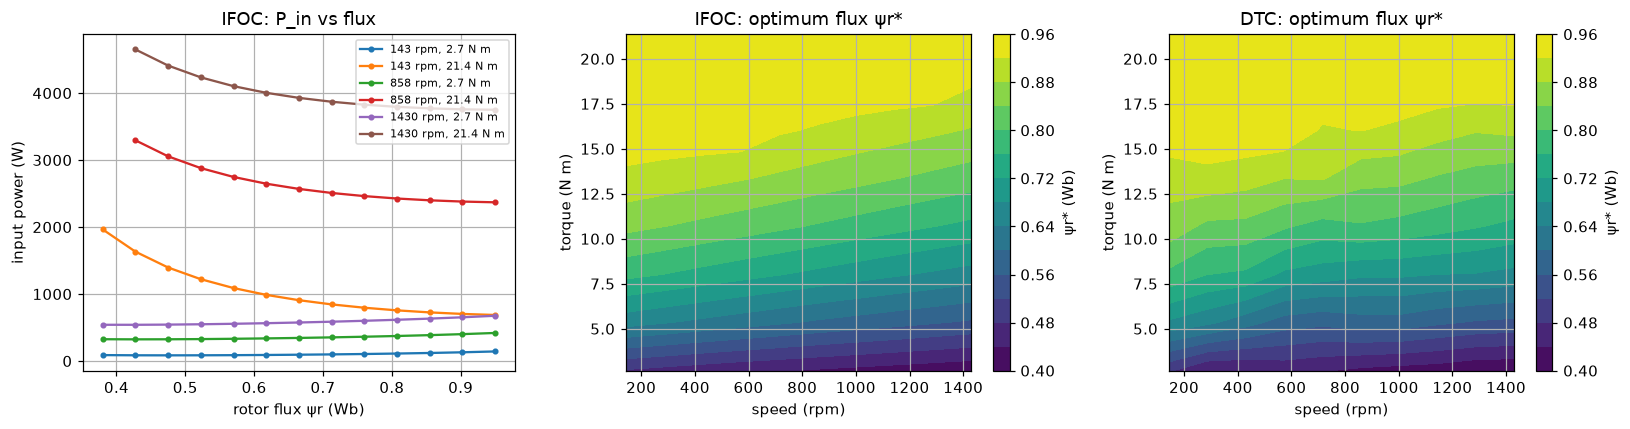

In [19]:
# Figures: P_in vs flux for a few points, and the optimum-flux map
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df = sweeps['IFOC'];  nom = df[df.Rr == df.Rr.mode()[0]]
ws = np.sort(nom.w.unique());  Ts_ = np.sort(nom['T'].unique())
for w in ws[[0, len(ws)//2, -1]]:
    for T in Ts_[[0, -1]]:
        g = nom[(nom.w == w) & (nom['T'] == T)].sort_values('psi')
        ax[0].plot(g.psi, g.Pin, 'o-', ms=3, label=f'{w*60/2/np.pi:.0f} rpm, {T:.1f} N m')
ax[0].set_xlabel('rotor flux ψr (Wb)'); ax[0].set_ylabel('input power (W)'); ax[0].set_title('IFOC: P_in vs flux')
ax[0].legend(fontsize=7)
for k, d in enumerate(DRIVES):
    o = opt[d]; o = o[o.Rr == o.Rr.mode()[0]]
    pv = o.pivot(index='T', columns='w', values='psi_opt')
    im = ax[k+1].contourf(pv.columns * 60 / 2 / np.pi, pv.index, pv.values, 15, cmap='viridis')
    plt.colorbar(im, ax=ax[k+1], label='ψr* (Wb)')
    ax[k+1].set_xlabel('speed (rpm)'); ax[k+1].set_ylabel('torque (N m)'); ax[k+1].set_title(f'{d}: optimum flux ψr*')
plt.tight_layout(); plt.savefig(OUT / 'fig_flux_optimum.png', dpi=200); plt.show()

## 3. Data split (70/15/15 over operating points) and helper functions
Inputs: speed ω (rad/s) and torque Te (N m) — the same inputs `flux_target` in `ctrl_step.m` uses.
If the sweep contains rotor-resistance variants (Rr ≠ 1) they are kept in the data; the main models use
(ω, Te) only, as deployed in Simulink (a version with Rr as 3rd input is in Section 8).

In [20]:
def make_split(o, seed=SEED):
    idx = np.arange(len(o))
    tr, tmp = train_test_split(idx, test_size=0.30, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, random_state=seed)
    return tr, va, te

def P_at(sweep, w, T, rr, psi):
    """Input power at an arbitrary flux, interpolated from the sweep at that operating point."""
    g = sweep[(sweep.w == w) & (sweep['T'] == T) & (sweep.Rr == rr)].sort_values('psi')
    return np.interp(psi, g.psi.values, g.Pin.values)

def evaluate(name, drive, model_predict, o, sweep, idx, n_params):
    X = o[['w', 'T']].values[idx];  y = o.psi_opt.values[idx]
    t0 = time.perf_counter();  yp = np.asarray(model_predict(X)).ravel();  dt = time.perf_counter() - t0
    yp = np.clip(yp, PSI_MIN, PSI_RATED)
    pen_W = np.array([P_at(sweep, *o[['w', 'T', 'Rr']].values[i], p) for i, p in zip(idx, yp)]) - o.P_opt.values[idx]
    pen_pct = 100 * pen_W / o.P_opt.values[idx]
    return dict(drive=drive, model=name, RMSE_mWb=1e3 * np.sqrt(mean_squared_error(y, yp)), R2=r2_score(y, yp),
                penalty_W_mean=pen_W.mean(), penalty_W_max=pen_W.max(), penalty_pct_mean=pen_pct.mean(),
                params=n_params, infer_us_per_sample=1e6 * dt / len(idx))

## 4. The four models
* **Polynomial**: scaled inputs → polynomial features (degree 2–5) → ridge regression.
* **XGBoost**: gradient-boosted trees [29].
* **MLP 2-10-1 (tanh)**: exactly the network that `flux_target` evaluates in MATLAB:
  `y = W2*tanh(W1*xn + b1) + b2`, `xn = (x - x_mu)./x_sd`, `psi = y*y_sd + y_mu`.
* **KAN [30]**: Kolmogorov–Arnold network with learnable cubic B-spline functions on every edge
  (width 2 → H → 1), implemented below in plain PyTorch (efficient-KAN formulation), so no extra package is needed.

In [21]:
# ---------- MLP 2-10-1 ----------
class MLPReg(RegressorMixin, BaseEstimator):
    def __init__(self, nh=10, wd=1e-4, restarts=3, epochs=1000, seed=SEED):
        self.nh, self.wd, self.restarts, self.epochs, self.seed = nh, wd, restarts, epochs, seed
    def fit(self, X, y):
        self.x_mu, self.x_sd = X.mean(0), X.std(0) + 1e-9
        self.y_mu, self.y_sd = y.mean(), y.std() + 1e-9
        Xn = torch.tensor((X - self.x_mu) / self.x_sd, dtype=torch.float64)
        yn = torch.tensor((y - self.y_mu) / self.y_sd, dtype=torch.float64).view(-1, 1)
        best = None
        for r in range(self.restarts):
            torch.manual_seed(self.seed + r)
            net = nn.Sequential(nn.Linear(2, self.nh), nn.Tanh(), nn.Linear(self.nh, 1)).double()
            opt_ = torch.optim.LBFGS(net.parameters(), lr=0.5, max_iter=self.epochs, history_size=50,
                                     line_search_fn='strong_wolfe', tolerance_grad=1e-10, tolerance_change=1e-14)
            def closure():
                opt_.zero_grad()
                loss = F.mse_loss(net(Xn), yn) + self.wd * sum((p**2).sum() for n_, p in net.named_parameters() if 'weight' in n_)
                loss.backward(); return loss
            opt_.step(closure)
            l = F.mse_loss(net(Xn), yn).item()
            if best is None or l < best[0]: best = (l, net)
        self.net = best[1]; return self
    def predict(self, X):
        with torch.no_grad():
            Xn = torch.tensor((X - self.x_mu) / self.x_sd, dtype=torch.float64)
            return self.net(Xn).numpy().ravel() * self.y_sd + self.y_mu
    def n_params(self):
        return sum(p.numel() for p in self.net.parameters())
    def to_matlab(self):
        W1 = self.net[0].weight.detach().numpy(); b1 = self.net[0].bias.detach().numpy().reshape(-1, 1)
        W2 = self.net[2].weight.detach().numpy(); b2 = float(self.net[2].bias.detach().numpy()[0])
        return dict(W1=W1, b1=b1, W2=W2, b2=b2, x_mu=self.x_mu.reshape(-1, 1), x_sd=self.x_sd.reshape(-1, 1),
                    y_mu=float(self.y_mu), y_sd=float(self.y_sd))

def mlp_matlab_forward(m, X):
    """Exactly the MATLAB formula in flux_target (used to check the export)."""
    xn = (X.T - m['x_mu']) / m['x_sd']
    y = m['W2'] @ np.tanh(m['W1'] @ xn + m['b1']) + m['b2']
    return (y * m['y_sd'] + m['y_mu']).ravel()

# ---------- KAN ----------
class KANLinear(nn.Module):
    """KAN layer: phi_ij(x) = w_b*silu(x) + sum_k c_ijk B_k(x), cubic B-splines on a uniform grid."""
    def __init__(self, nin, nout, G=5, k=3, lo=-1.0, hi=1.0):
        super().__init__()
        h = (hi - lo) / G
        self.register_buffer('grid', torch.arange(-k, G + k + 1, dtype=torch.float64) * h + lo)
        self.k, self.lo, self.hi = k, lo, hi
        self.base = nn.Linear(nin, nout).double()
        self.coef = nn.Parameter(0.1 * torch.randn(nout, nin, G + k, dtype=torch.float64))
    def bsplines(self, x):
        g = self.grid;  x = x.clamp(self.lo, self.hi - 1e-9).unsqueeze(-1)
        B = ((x >= g[:-1]) & (x < g[1:])).to(x.dtype)
        for p in range(1, self.k + 1):
            B = (x - g[:-(p + 1)]) / (g[p:-1] - g[:-(p + 1)]) * B[..., :-1] + \
                (g[p + 1:] - x) / (g[p + 1:] - g[1:-p]) * B[..., 1:]
        return B
    def forward(self, x):
        return self.base(F.silu(x)) + torch.einsum('bik,oik->bo', self.bsplines(x), self.coef)

class KANReg(RegressorMixin, BaseEstimator):
    def __init__(self, hidden=4, G=5, wd=1e-5, epochs=300, seed=SEED):
        self.hidden, self.G, self.wd, self.epochs, self.seed = hidden, G, wd, epochs, seed
    def fit(self, X, y):
        self.x_lo, self.x_hi = X.min(0), X.max(0)
        self.y_mu, self.y_sd = y.mean(), y.std() + 1e-9
        Xn = torch.tensor(self._xn(X));  yn = torch.tensor((y - self.y_mu) / self.y_sd).view(-1, 1)
        torch.manual_seed(self.seed)
        self.net = nn.Sequential(KANLinear(2, self.hidden, self.G, lo=-1, hi=1),
                                 KANLinear(self.hidden, 1, self.G, lo=-3, hi=3))
        opt_ = torch.optim.LBFGS(self.net.parameters(), lr=0.5, max_iter=self.epochs, history_size=50,
                                 line_search_fn='strong_wolfe')
        def closure():
            opt_.zero_grad()
            loss = F.mse_loss(self.net(Xn), yn) + self.wd * sum((p**2).sum() for p in self.net.parameters())
            loss.backward(); return loss
        opt_.step(closure);  return self
    def _xn(self, X):
        return 2 * (X - self.x_lo) / (self.x_hi - self.x_lo + 1e-12) - 1
    def predict(self, X):
        with torch.no_grad():
            return self.net(torch.tensor(self._xn(X))).numpy().ravel() * self.y_sd + self.y_mu
    def n_params(self):
        return sum(p.numel() for p in self.net.parameters())

## 5. Train, tune (5-fold CV on the training set) and test — for each drive
Hyper-parameters are chosen with the **one-standard-error rule**: of all settings whose 5-fold CV error is within
one standard error of the best, the simplest (most regularized) is taken. With only ~60–70 training points per
drive this protects against over-fitting — a 41-parameter MLP can otherwise fit the label noise.

In [22]:
cv = KFold(5, shuffle=True, random_state=SEED)
# Hyper-parameter grids reach far into the strongly-regularized side, so that the selection rule below
# can trade a little training accuracy for a model that generalizes.
grids = {
    'Polynomial': (make_pipeline(StandardScaler(), PolynomialFeatures(), Ridge()),
                   {'polynomialfeatures__degree': [2, 3, 4, 5], 'ridge__alpha': [1e-6, 1e-4, 1e-2, 1e-1, 1.0]}),
    'MLP 2-10-1': (MLPReg(), {'wd': [0.0, 1e-5, 1e-4, 1e-3, 1e-2, 3e-2]}),
    'KAN':        (KANReg(), {'hidden': [2, 3, 5], 'G': [3, 5], 'wd': [1e-5, 1e-4, 1e-3, 1e-2]}),
}
if HAS_XGB:
    grids['XGBoost'] = (XGBRegressor(random_state=SEED, n_jobs=4, verbosity=0, subsample=0.8),
                        {'n_estimators': [100, 300, 600], 'max_depth': [2, 3, 4], 'learning_rate': [0.03, 0.1],
                         'min_child_weight': [1, 3, 6], 'reg_lambda': [1, 10]})

# Simplicity order used by the one-standard-error rule (smaller key = simpler / more regularized model)
def simplicity(name, p):
    if name == 'Polynomial': return (p['polynomialfeatures__degree'], -p['ridge__alpha'])
    if name == 'MLP 2-10-1': return (-p['wd'],)
    if name == 'KAN':        return (p['hidden'], p['G'], -p['wd'])
    return (p['max_depth'], p['n_estimators'], -p['min_child_weight'], -p['reg_lambda'], p['learning_rate'])

def one_se_choice(name, gs, k=5):
    """One-standard-error rule (Breiman et al., 1984; Hastie et al., ESL 7.10): among all settings whose CV error
    is within one standard error of the best, take the SIMPLEST. Guards against picking a setting that only
    looks best by chance on 5 folds - i.e. against over-fitting the hyper-parameters."""
    mse = -gs.cv_results_['mean_test_score'];  se = gs.cv_results_['std_test_score'] / np.sqrt(k)
    b = int(np.argmin(mse));  ok = np.where(mse <= mse[b] + se[b])[0]
    return int(min(ok, key=lambda i: simplicity(name, gs.cv_results_['params'][i])))

def n_params_of(name, est):
    if name == 'Polynomial':
        return est[-1].coef_.size + 1
    if name == 'XGBoost':
        return int(sum(len(t.splitlines()) for t in est.get_booster().get_dump()))   # ~ number of tree nodes
    return est.n_params()

results, fitted, splits = [], {}, {}
for d in DRIVES:
    o = opt[d];  tr, va, te = make_split(o);  splits[d] = (tr, va, te)
    X = o[['w', 'T']].values;  y = o.psi_opt.values
    trva = np.concatenate([tr, va])
    for name, (est, grid) in grids.items():
        t0 = time.time()
        gs = GridSearchCV(est, grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=1, refit=False)
        gs.fit(X[tr], y[tr])
        # clone(): a fresh model for every drive (re-using one object would overwrite the other drive's model)
        ci = one_se_choice(name, gs);  chosen = gs.cv_results_['params'][ci]
        best = clone(est).set_params(**chosen)
        # validation score with the chosen hyper-parameters, then refit on train+val for the test
        best.fit(X[tr], y[tr]);  val = np.sqrt(mean_squared_error(y[va], best.predict(X[va])))
        best.fit(X[trva], y[trva])
        fitted[(d, name)] = best
        r = evaluate(name, d, best.predict, o, sweeps[d], te, n_params_of(name, best))
        r['val_RMSE_mWb'] = 1e3 * val;  r['best_hparams'] = json.dumps(chosen, default=float);  r['train_s'] = time.time() - t0
        # fit diagnostics: error on the data it was trained on, and 5-fold CV error (mean, std)
        r['train_RMSE_mWb'] = 1e3 * np.sqrt(mean_squared_error(y[trva], best.predict(X[trva])))
        r['train_R2'] = r2_score(y[trva], best.predict(X[trva]))
        cv_mse = -gs.cv_results_['mean_test_score'][ci]
        cv_sd = gs.cv_results_['std_test_score'][ci]
        r['cv_RMSE_mWb'] = 1e3 * np.sqrt(cv_mse)
        r['cv_RMSE_sd_mWb'] = 1e3 * cv_sd / (2 * np.sqrt(cv_mse) + 1e-12)       # delta-method std of RMSE
        results.append(r)
        print(f'{d:5s} {name:12s} test RMSE {r["RMSE_mWb"]:6.2f} mWb  R2 {r["R2"]:.4f}  '
              f'penalty {r["penalty_W_mean"]:6.2f} W ({r["penalty_pct_mean"]:.2f} %)  [{r["train_s"]:.0f} s]  {chosen}')

res = pd.DataFrame(results)
res.to_csv(OUT / 'flux_model_comparison.csv', index=False)
res[['drive', 'model', 'RMSE_mWb', 'R2', 'penalty_W_mean', 'penalty_W_max', 'penalty_pct_mean', 'params', 'infer_us_per_sample']].round(4)

IFOC  Polynomial   test RMSE   1.66 mWb  R2 0.9999  penalty   0.16 W (0.02 %)  [0 s]  {'polynomialfeatures__degree': 4, 'ridge__alpha': 0.1}
IFOC  MLP 2-10-1   test RMSE   1.03 mWb  R2 1.0000  penalty   0.17 W (0.02 %)  [128 s]  {'wd': 0.0}
IFOC  KAN          test RMSE   2.16 mWb  R2 0.9999  penalty   0.21 W (0.03 %)  [88 s]  {'G': 3, 'hidden': 5, 'wd': 1e-05}
IFOC  XGBoost      test RMSE   6.97 mWb  R2 0.9988  penalty   0.38 W (0.04 %)  [22 s]  {'learning_rate': 0.1, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 300, 'reg_lambda': 1}
DTC   Polynomial   test RMSE   6.55 mWb  R2 0.9990  penalty   0.21 W (0.03 %)  [0 s]  {'polynomialfeatures__degree': 3, 'ridge__alpha': 0.1}
DTC   MLP 2-10-1   test RMSE   7.43 mWb  R2 0.9987  penalty   0.24 W (0.04 %)  [124 s]  {'wd': 0.0001}
DTC   KAN          test RMSE   9.87 mWb  R2 0.9976  penalty   0.20 W (0.04 %)  [89 s]  {'G': 3, 'hidden': 5, 'wd': 1e-05}
DTC   XGBoost      test RMSE   9.07 mWb  R2 0.9980  penalty   0.27 W (0.03 %)  [22 s

,drive,model,RMSE_mWb,R2,penalty_W_mean,penalty_W_max,penalty_pct_mean,params,infer_us_per_sample
0,IFOC,Polynomial,1.6566,0.9999,0.1632,0.3671,0.0242,16,34.5000
1,IFOC,MLP 2-10-1,1.0265,1.0000,0.1688,0.3665,0.0240,41,11.0000
2,IFOC,KAN,2.1559,0.9999,0.2088,0.4579,0.0283,111,63.4000
3,IFOC,XGBoost,6.9716,0.9988,0.3783,2.4130,0.0357,1958,35.6000
4,DTC,Polynomial,6.5497,0.9990,0.2071,0.5615,0.0337,11,31.4833
5,DTC,MLP 2-10-1,7.4337,0.9987,0.2444,0.4492,0.0382,41,12.1417
6,DTC,KAN,9.8731,0.9976,0.2039,0.4837,0.0408,111,65.1250
7,DTC,XGBoost,9.0728,0.9980,0.2746,1.2486,0.0326,1960,39.5750


## 5b. Over-fitting / under-fitting check
Three errors per model: **train** (data it was fitted on), **CV** (5-fold cross-validation on the training set,
mean ± std) and **test** (15 % held-out points never used for training or tuning).

Rules (fixed before looking at the results):
* **Under-fit** — the model cannot even fit its *own training data* as well as the best model of that drive
  predicts *unseen* data: train RMSE > lowest CV RMSE of any model for that drive. It is too simple for the
  ψr*(ω, Te) surface. (A fixed threshold would be unfair: the DTC labels are noisier than the IFOC labels
  because DTC's hysteresis switching makes the measured input power ripple, so every model has a higher error floor.)
* **Over-fit** — small training error but much larger **cross-validation** error: CV RMSE > 2 × train RMSE **and**
  test − train > `GAP_TOL` (3 mWb). The model has memorised the training points.
* Otherwise **good fit**. Test RMSE inside the CV band (mean ± 2 std) confirms the test result is not luck.

The flux labels themselves carry noise (P_in from a switching simulation, 13 flux levels), so a train RMSE of
exactly 0 is *not* the goal — it would mean the model is fitting that noise.

In [23]:
UNDER_TOL, GAP_TOL = 10.0, 3.0      # mWb (UNDER_TOL is only drawn as a reference line on the learning curves)
best_cv = res.groupby('drive').cv_RMSE_mWb.min()
def verdict(r):
    if r.train_RMSE_mWb > best_cv[r.drive]:
        return 'UNDER-FIT'
    gen = max(r.cv_RMSE_mWb, r.RMSE_mWb)          # CV (5 folds) is the reliable estimate; test is only ~12 points
    if gen > 2 * r.train_RMSE_mWb and gen - r.train_RMSE_mWb > GAP_TOL:
        return 'OVER-FIT'
    return 'good fit'
res['fit'] = res.apply(verdict, axis=1)
res['test_in_CV_band'] = (res.RMSE_mWb <= res.cv_RMSE_mWb + 2 * res.cv_RMSE_sd_mWb)
fitdiag = res[['drive', 'model', 'train_RMSE_mWb', 'cv_RMSE_mWb', 'cv_RMSE_sd_mWb', 'val_RMSE_mWb', 'RMSE_mWb',
               'train_R2', 'R2', 'fit', 'test_in_CV_band']].rename(columns={'RMSE_mWb': 'test_RMSE_mWb', 'R2': 'test_R2'})
fitdiag.to_csv(OUT / 'table_flux_fit_check.csv', index=False)
print(fitdiag.round(3).to_string(index=False))

drive      model  train_RMSE_mWb  cv_RMSE_mWb  cv_RMSE_sd_mWb  val_RMSE_mWb  test_RMSE_mWb  train_R2  test_R2       fit  test_in_CV_band
 IFOC Polynomial           4.560        7.260           2.422         7.692          1.657     0.999    1.000 UNDER-FIT             True
 IFOC MLP 2-10-1           0.454        4.058           1.284        21.822          1.026     1.000    1.000  OVER-FIT             True
 IFOC        KAN           2.292        4.813           1.245         8.007          2.156     1.000    1.000  good fit             True
 IFOC    XGBoost           2.517        8.426           2.027         4.658          6.972     1.000    0.999  OVER-FIT             True
  DTC Polynomial          11.437       14.350           4.111        12.864          6.550     0.995    0.999  good fit             True
  DTC MLP 2-10-1           6.577       13.129           3.152         9.468          7.434     0.998    0.999  good fit             True
  DTC        KAN           4.483       12

**Learning curves** — train and CV error versus the number of training points.
Good fit: the two curves come together at a low error. Under-fit: both curves stay high.
Over-fit: a large gap that stays open as data is added.

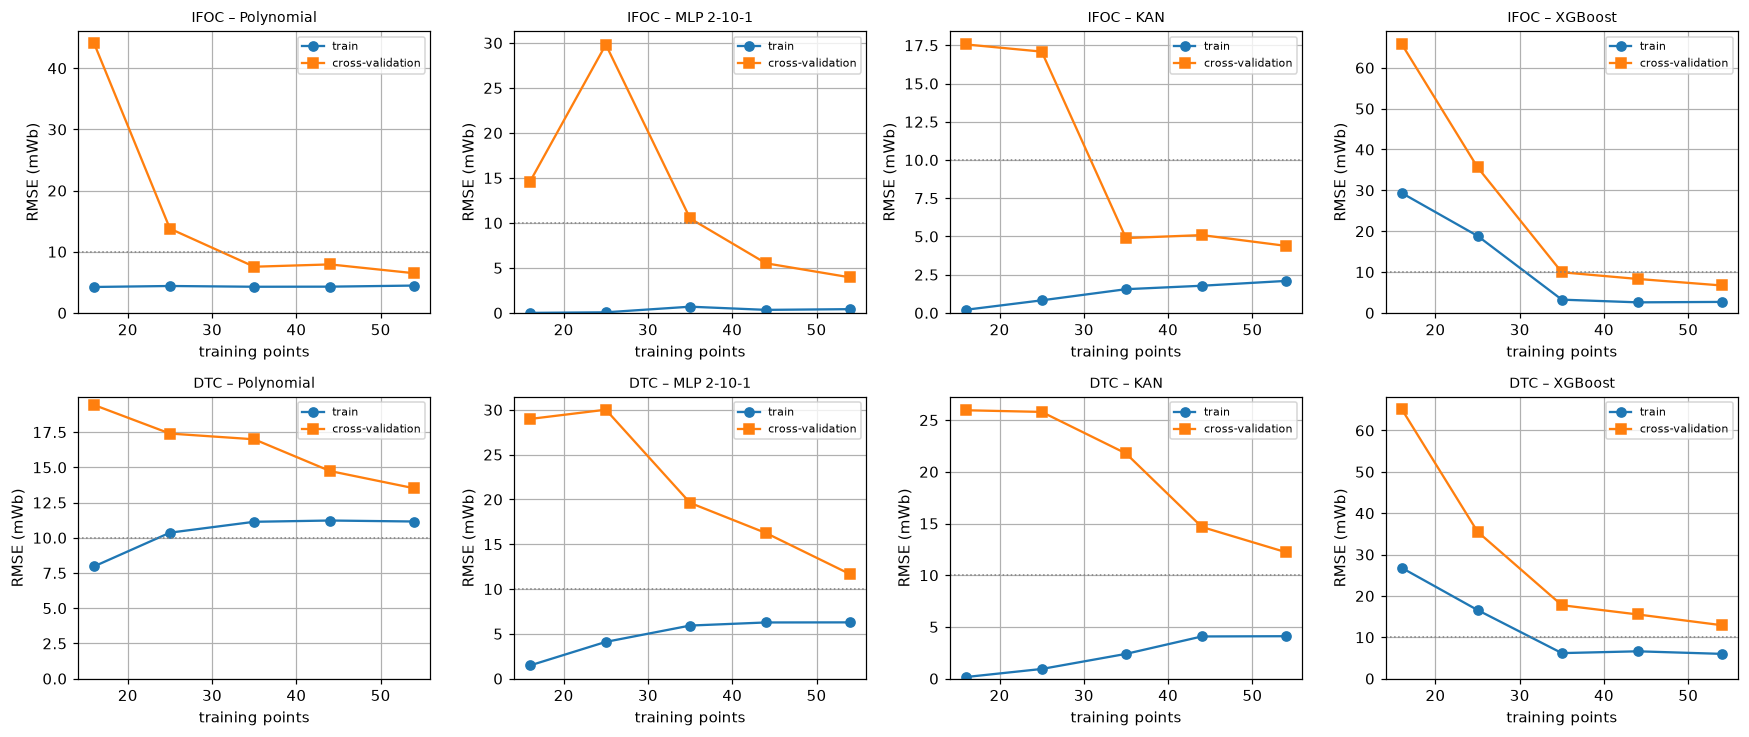

In [24]:
fig, ax = plt.subplots(len(DRIVES), len(grids), figsize=(4 * len(grids), 3.4 * len(DRIVES)), squeeze=False)
for i, d in enumerate(DRIVES):
    o = opt[d];  tr, va, te = splits[d];  trva = np.concatenate([tr, va])
    X = o[['w', 'T']].values;  y = o.psi_opt.values
    for j, name in enumerate(grids):
        est = clone(fitted[(d, name)])
        sizes, tr_sc, cv_sc = learning_curve(est, X[trva], y[trva], cv=KFold(5, shuffle=True, random_state=SEED),
                                             train_sizes=np.linspace(0.3, 1.0, 5), scoring='neg_mean_squared_error', n_jobs=1)
        trm, cvm = 1e3 * np.sqrt(-tr_sc.mean(1)), 1e3 * np.sqrt(-cv_sc.mean(1))
        a = ax[i, j]
        a.plot(sizes, trm, 'o-', label='train');  a.plot(sizes, cvm, 's-', label='cross-validation')
        a.axhline(UNDER_TOL, color='grey', ls=':', lw=1)
        a.set_title(f'{d} – {name}', fontsize=9);  a.set_xlabel('training points');  a.set_ylabel('RMSE (mWb)')
        a.legend(fontsize=7);  a.set_ylim(bottom=0)
plt.tight_layout(); plt.savefig(OUT / 'fig_flux_learning_curves.png', dpi=200); plt.show()

## 6. Pick the best model per drive and plot predictions
Rule (proposal 5.4 step 5): the most accurate model in **efficiency penalty** (ties → RMSE) that can run every
control step. All four can: the MLP directly in the MATLAB Function block, the others as a look-up table.

IFOC: best = Polynomial  (penalty 0.16 W, RMSE 1.66 mWb)
DTC: best = KAN  (penalty 0.20 W, RMSE 9.87 mWb)


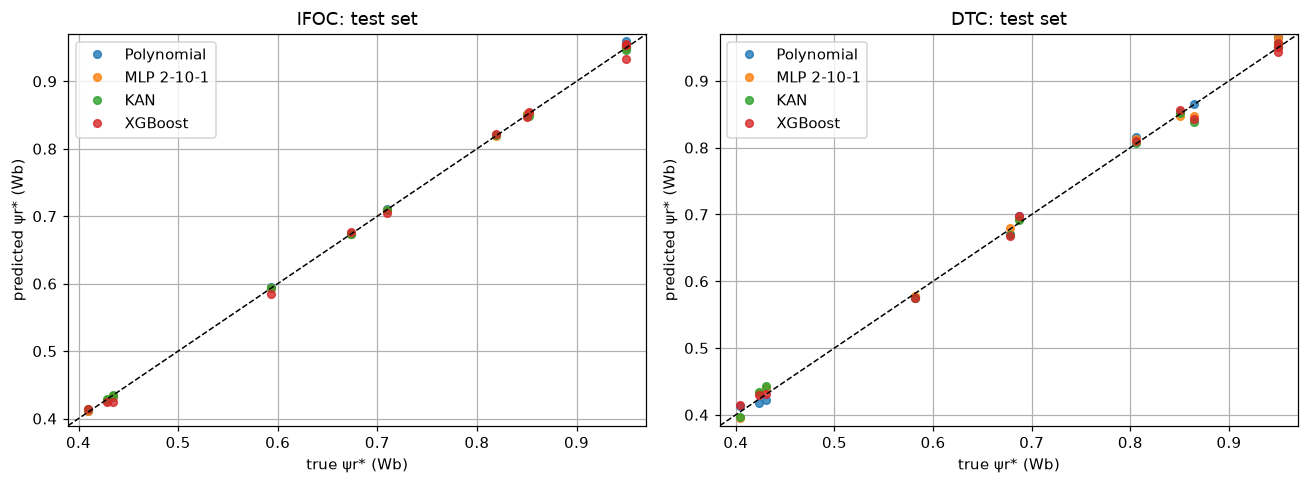

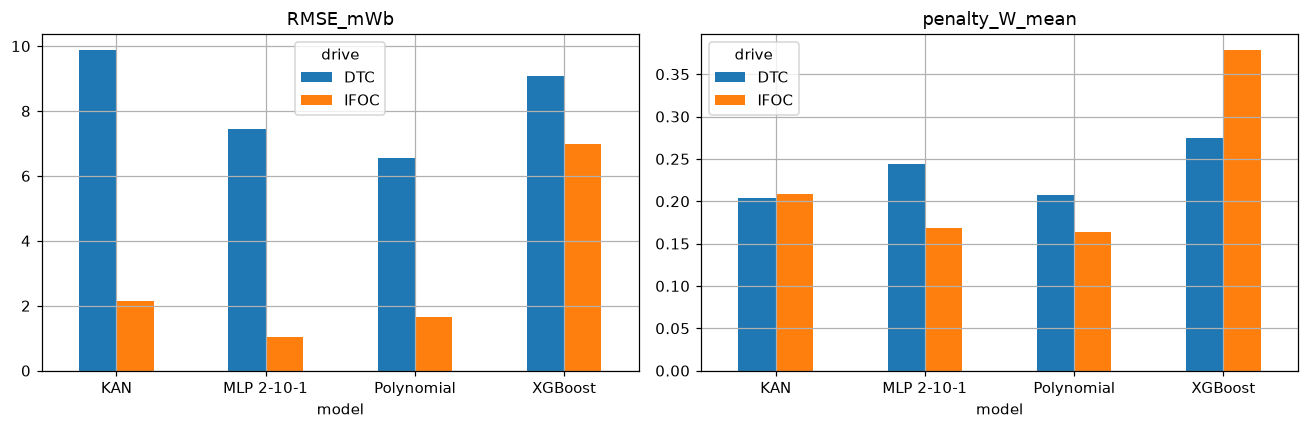

In [25]:
best_model = {}
for d in DRIVES:
    r = res[res.drive == d].sort_values(['penalty_W_mean', 'RMSE_mWb'])
    best_model[d] = r.iloc[0].model
    print(f'{d}: best = {best_model[d]}  (penalty {r.iloc[0].penalty_W_mean:.2f} W, RMSE {r.iloc[0].RMSE_mWb:.2f} mWb)')
(OUT / 'best_flux_model.json').write_text(json.dumps(best_model, indent=2))

fig, ax = plt.subplots(1, len(DRIVES), figsize=(6 * len(DRIVES), 4.5))
ax = np.atleast_1d(ax)
for k, d in enumerate(DRIVES):
    o = opt[d];  te = splits[d][2]
    lims = [o.psi_opt.min() - 0.02, o.psi_opt.max() + 0.02]
    for name in grids:
        yp = fitted[(d, name)].predict(o[['w', 'T']].values[te])
        ax[k].plot(o.psi_opt.values[te], yp, 'o', ms=5, alpha=0.8, label=name)
    ax[k].plot(lims, lims, 'k--', lw=1); ax[k].set_xlim(lims); ax[k].set_ylim(lims)
    ax[k].set_xlabel('true ψr* (Wb)'); ax[k].set_ylabel('predicted ψr* (Wb)'); ax[k].set_title(f'{d}: test set'); ax[k].legend()
plt.tight_layout(); plt.savefig(OUT / 'fig_flux_pred_vs_true.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, met in enumerate(['RMSE_mWb', 'penalty_W_mean']):
    pv = res.pivot(index='model', columns='drive', values=met)
    pv.plot.bar(ax=ax[k], rot=0); ax[k].set_title(met)
plt.tight_layout(); plt.savefig(OUT / 'fig_flux_metrics.png', dpi=200); plt.show()

## 7. Export to MATLAB
* **MLP** → `mlp_<DRIVE>.mat` (struct `mlp`, same fields as `P.mlp`). In MATLAB:
  ```matlab
  P = default_params('IFOC');
  S = load(fullfile('python_out','mlp_IFOC.mat'));  P.mlp = S.mlp;  P.ctrl.flux_mode = 4;
  ```
* **Any model as a look-up table** → `lut_<MODEL>_<DRIVE>.csv` with columns `w,T,psi` on the `P.lut` grid
  (10 speeds × 10 torques, speed outer loop). In MATLAB: `P = build_flux_lut(P,'csv',file); P.ctrl.flux_mode = 3;`
* **Check file** `mlp_check_<DRIVE>.csv`: inputs and Python outputs; MATLAB must give the same ψ (≤ 1e-9).

In [26]:
for d in DRIVES:
    m = fitted[(d, 'MLP 2-10-1')].to_matlab()
    savemat(OUT / f'mlp_{d}.mat', {'mlp': m})
    o = opt[d];  te = splits[d][2];  X = o[['w', 'T']].values[te]
    py = fitted[(d, 'MLP 2-10-1')].predict(X);  mf = mlp_matlab_forward(m, X)
    print(f'{d}: MLP exported; max |torch - MATLAB-formula| = {np.abs(py - mf).max():.2e}')
    pd.DataFrame({'w': X[:, 0], 'T': X[:, 1], 'psi_python': mf}).to_csv(OUT / f'mlp_check_{d}.csv', index=False)
    Wg, Tg = np.meshgrid(LUT_W, LUT_T, indexing='ij')
    grid = np.c_[Wg.ravel(), Tg.ravel()]
    for name in grids:
        psi = np.clip(fitted[(d, name)].predict(grid), PSI_MIN, PSI_RATED)
        tag = name.split()[0].lower()
        pd.DataFrame({'w': grid[:, 0], 'T': grid[:, 1], 'psi': psi}).to_csv(OUT / f'lut_{tag}_{d}.csv', index=False)
print('Files written to', OUT.resolve())
print(sorted(p.name for p in OUT.iterdir()))

IFOC: MLP exported; max |torch - MATLAB-formula| = 5.55e-16
DTC: MLP exported; max |torch - MATLAB-formula| = 1.11e-16
Files written to C:\Users\ironman\Desktop\New folder (2)\Electrical Drive\python_out
['best_flux_model.json', 'fault_model_comparison.csv', 'fault_model_comparison_aug.csv', 'fault_noise_robustness.csv', 'fault_noise_robustness_aug.csv', 'fig_fault_confusion.png', 'fig_fault_confusion_aug.png', 'fig_fault_examples.png', 'fig_fault_learning.png', 'fig_fault_loss_curves.png', 'fig_fault_loss_curves_aug.png', 'fig_flux_learning_curves.png', 'fig_flux_metrics.png', 'fig_flux_optimum.png', 'fig_flux_pred_vs_true.png', 'flux_model_comparison.csv', 'lut_kan_DTC.csv', 'lut_kan_IFOC.csv', 'lut_mlp_DTC.csv', 'lut_mlp_IFOC.csv', 'lut_polynomial_DTC.csv', 'lut_polynomial_IFOC.csv', 'lut_xgboost_DTC.csv', 'lut_xgboost_IFOC.csv', 'mlp_DTC.mat', 'mlp_IFOC.mat', 'mlp_check_DTC.csv', 'mlp_check_IFOC.csv', 'table_fault_fit_check.csv', 'table_fault_fit_check_aug.csv', 'table_fault_models

**MATLAB check of the MLP export** (paste in MATLAB, from the `Electrical Drive` folder):
```matlab
S = load(fullfile('python_out','mlp_IFOC.mat'));  m = S.mlp;
C = readtable(fullfile('python_out','mlp_check_IFOC.csv'));
xn = ([C.w C.T]' - m.x_mu)./m.x_sd;
psi = (m.W2*tanh(m.W1*xn + m.b1) + m.b2)*m.y_sd + m.y_mu;
fprintf('max difference MATLAB vs Python = %.2e\n', max(abs(psi(:) - C.psi_python)));
```

## 8. (Optional) Rotor-resistance input, as in [10]
Only runs if the sweep contains several Rr levels. Shows how much accuracy an Rr estimate would add.

In [27]:
for d in DRIVES:
    o = opt[d]
    if o.Rr.nunique() < 2:
        print(f'{d}: only one Rr level in the sweep -> skipped'); continue
    X2 = o[['w', 'T', 'Rr']].values;  y = o.psi_opt.values;  tr, va, te = splits[d]
    for name, X_ in [('(w,T)', o[['w', 'T']].values), ('(w,T,Rr)', X2)]:
        est = make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(1e-4)).fit(X_[np.r_[tr, va]], y[np.r_[tr, va]])
        print(f'{d} polynomial with inputs {name:9s}: test RMSE {1e3*np.sqrt(mean_squared_error(y[te], est.predict(X_[te]))):.2f} mWb')

IFOC: only one Rr level in the sweep -> skipped
DTC: only one Rr level in the sweep -> skipped


## 9. Summary table for the thesis
Copy this into the results chapter (RQ3 / RQ5). `penalty` = extra input power at the predicted flux compared
with the true optimum (lower is better); `saving` = input-power saving of the true optimum vs rated flux.

In [28]:
summ = res[['drive', 'model', 'train_RMSE_mWb', 'cv_RMSE_mWb', 'RMSE_mWb', 'R2', 'fit', 'penalty_W_mean', 'penalty_pct_mean', 'params', 'infer_us_per_sample']].copy()
for d in DRIVES:
    summ.loc[summ.drive == d, 'mean_saving_vs_rated_%'] = opt[d].saving_pct.mean()
summ = summ.round(3)
summ.to_csv(OUT / 'table_flux_models.csv', index=False)
print(summ.to_string(index=False))

drive      model  train_RMSE_mWb  cv_RMSE_mWb  RMSE_mWb    R2       fit  penalty_W_mean  penalty_pct_mean  params  infer_us_per_sample  mean_saving_vs_rated_%
 IFOC Polynomial           4.560        7.260     1.657 1.000 UNDER-FIT           0.163             0.024      16               34.500                   5.450
 IFOC MLP 2-10-1           0.454        4.058     1.026 1.000  OVER-FIT           0.169             0.024      41               11.000                   5.450
 IFOC        KAN           2.292        4.813     2.156 1.000  good fit           0.209             0.028     111               63.400                   5.450
 IFOC    XGBoost           2.517        8.426     6.972 0.999  OVER-FIT           0.378             0.036    1958               35.600                   5.450
  DTC Polynomial          11.437       14.350     6.550 0.999  good fit           0.207             0.034      11               31.483                   5.602
  DTC MLP 2-10-1           6.577       13.129 